## Data Transformation
Continuing from the eda.ipynb, here we will transform the data so it can be used for the training section

### 1. Load Data 
Same as eda part, we just copy some of the preprocessing code from datapreprocessing.ipynb

In [3]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import joblib
import numpy as np

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
from imblearn.over_sampling import SMOTE

RANDOM_STATE = 42

In [4]:
raw_folder = Path('Dataset/raw')
if not raw_folder.exists():
    raw_folder = Path('../Dataset/raw')

df = pd.read_csv(raw_folder / 'SouthGermanCredit.asc', sep=r'\s+')
print('Shape:', df.shape)
print('Total nulls:', df.isna().sum().sum())
print('Duplicate rows:', df.duplicated().sum())

Shape: (1000, 21)
Total nulls: 0
Duplicate rows: 0


In [5]:
rename_map = {'laufkont': 'status',
 'laufzeit': 'duration',
 'moral': 'credit_history',
 'verw': 'purpose',
 'hoehe': 'amount',
 'sparkont': 'savings',
 'beszeit': 'employment_duration',
 'rate': 'installment_rate',
 'famges': 'personal_status_sex',
 'buerge': 'other_debtors',
 'wohnzeit': 'present_residence',
 'verm': 'property',
 'alter': 'age',
 'weitkred': 'other_installment_plans',
 'wohn': 'housing',
 'bishkred': 'number_credits',
 'beruf': 'job',
 'pers': 'people_liable',
 'telef': 'telephone',
 'gastarb': 'foreign_worker',
 'kredit': 'credit_risk'}

df = df.rename(columns=rename_map)

In [6]:
category_mappings = {'status': {1: 'no checking account',
            2: '... < 0 DM',
            3: '0<= ... < 200 DM',
            4: '... >= 200 DM / salary for at least 1 year'},
 'credit_history': {0: 'delay in paying off in the past',
                    1: 'critical account/other credits elsewhere',
                    2: 'no credits taken/all credits paid back duly',
                    3: 'existing credits paid back duly till now',
                    4: 'all credits at this bank paid back duly'},
 'purpose': {0: 'others',
             1: 'car (new)',
             2: 'car (used)',
             3: 'furniture/equipment',
             4: 'radio/television',
             5: 'domestic appliances',
             6: 'repairs',
             7: 'education',
             8: 'vacation',
             9: 'retraining',
             10: 'business'},
 'savings': {1: 'unknown/no savings account',
             2: '... <  100 DM',
             3: '100 <= ... <  500 DM',
             4: '500 <= ... < 1000 DM',
             5: '... >= 1000 DM'},
 'employment_duration': {1: 'unemployed',
                         2: '< 1 yr',
                         3: '1 <= ... < 4 yrs',
                         4: '4 <= ... < 7 yrs',
                         5: '>= 7 yrs'},
 'installment_rate': {1: '>= 35', 2: '25 <= ... < 35', 3: '20 <= ... < 25', 4: '< 20'},
 'personal_status_sex': {1: 'male : divorced/separated',
                         2: 'female : non-single or male : single',
                         3: 'male : married/widowed',
                         4: 'female : single'},
 'other_debtors': {1: 'none', 2: 'co-applicant', 3: 'guarantor'},
 'present_residence': {1: '< 1 yr', 2: '1 <= ... < 4 yrs', 3: '4 <= ... < 7 yrs', 4: '>= 7 yrs'},
 'property': {1: 'unknown / no property',
              2: 'car or other',
              3: 'building soc. savings agr./life insurance',
              4: 'real estate'},
 'other_installment_plans': {1: 'bank', 2: 'stores', 3: 'none'},
 'housing': {1: 'for free', 2: 'rent', 3: 'own'},
 'number_credits': {1: '1', 2: '2-3', 3: '4-5', 4: '>= 6'},
 'job': {1: 'unemployed/unskilled - non-resident',
         2: 'unskilled - resident',
         3: 'skilled employee/official',
         4: 'manager/self-empl./highly qualif. employee'},
 'people_liable': {1: '3 or more', 2: '0 to 2'},
 'telephone': {1: 'no', 2: 'yes (under customer name)'},
 'foreign_worker': {1: 'yes', 2: 'no'},
 'credit_risk': {0: 'bad', 1: 'good'}}

In [7]:
numerical_features = ['duration', 'amount', 'age']

nominal_features = [
    'status', 'credit_history', 'purpose', 'savings', 'personal_status_sex',
    'other_debtors', 'other_installment_plans', 'housing', 'people_liable',
    'telephone', 'foreign_worker'
]

ordinal_features = [
    'employment_duration', 'installment_rate', 'present_residence',
    'property', 'number_credits', 'job'
]

# Readable copy: replace each category code with its meaning.
eda_df = df.copy()
for column, mapping in category_mappings.items():
    eda_df[column] = pd.Categorical(df[column].map(mapping),
                                    categories=list(mapping.values()))

# 1 if the applicant is a bad credit risk, 0 otherwise (the mean of this is the bad rate).
eda_df['is_bad'] = (df['credit_risk'] == 0).astype(int)

bad_color = 'tab:red'
good_color = 'tab:blue'

display(eda_df.head())

,status,duration,credit_history,purpose,amount,savings,employment_duration,installment_rate,personal_status_sex,other_debtors,...,age,other_installment_plans,housing,number_credits,job,people_liable,telephone,foreign_worker,credit_risk,is_bad
0,no checking account,18,all credits at this bank paid back duly,car (used),1049,unknown/no savings account,< 1 yr,< 20,female : non-single or male : single,none,...,21,none,for free,1,skilled employee/official,0 to 2,no,no,good,0
1,no checking account,9,all credits at this bank paid back duly,others,2799,unknown/no savings account,1 <= ... < 4 yrs,25 <= ... < 35,male : married/widowed,none,...,36,none,for free,2-3,skilled employee/official,3 or more,no,no,good,0
2,... < 0 DM,12,no credits taken/all credits paid back duly,retraining,841,... < 100 DM,4 <= ... < 7 yrs,25 <= ... < 35,female : non-single or male : single,none,...,23,none,for free,1,unskilled - resident,0 to 2,no,no,good,0
3,no checking account,12,all credits at this bank paid back duly,others,2122,unknown/no savings account,1 <= ... < 4 yrs,20 <= ... < 25,male : married/widowed,none,...,39,none,for free,2-3,unskilled - resident,3 or more,no,yes,good,0
4,no checking account,12,all credits at this bank paid back duly,others,2171,unknown/no savings account,1 <= ... < 4 yrs,< 20,male : married/widowed,none,...,38,bank,rent,2-3,unskilled - resident,0 to 2,no,yes,good,0


### 2. Feature Engineering
added columns based on eda findings (in numerical features) just to make it simpler in the long run

The columns:
1. amount_per_month
-> duration and amount correlated as 0.62

2. is_young
-> applicants aged 25 being bad rated as high as 42% as opposed to 24% to 30% for older groups

3. long_duration
-> bad rate jumps to 52% for loans of 27 months or over

In [8]:
fe_df = df.copy()

fe_df['amount_per_month'] = fe_df['amount'] / fe_df['duration']
fe_df['is_young'] = (fe_df['age'] <= 25).astype(int)
fe_df['long_duration'] = (fe_df['duration'] > 36).astype(int)

# update the feature groups so it can be easier to be called in later steps
continuous_features = numerical_features + ['amount_per_month']
binary_flags = ['is_young', 'long_duration']

display(fe_df[continuous_features + binary_flags].describe().round(2))

print('missing values after feature engineering: ', fe_df.isna().sum().sum())

,duration,amount,age,amount_per_month,is_young,long_duration
count,1000.00,1000.00,1000.00,1000.00,1000.00,1000.00
mean,20.90,3271.25,35.54,167.69,0.19,0.09
std,12.06,2822.75,11.35,153.49,0.39,0.28
min,4.00,250.00,19.00,24.06,0.00,0.00
25%,12.00,1365.50,27.00,89.33,0.00,0.00
50%,18.00,2319.50,33.00,130.33,0.00,0.00
75%,24.00,3972.25,42.00,206.18,0.00,0.00
max,72.00,18424.00,75.00,2482.67,1.00,1.00


missing values after feature engineering:  0


### 3. Train-Test Split
split dataset into 70:30 for train:test split

In [9]:
X = fe_df.drop(columns='credit_risk')
y = fe_df['credit_risk']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, stratify=y, random_state=RANDOM_STATE
)

print('train:', X_train.shape)
print('test:', X_test.shape)
print('share of good (1) in train:', round(y_train.mean(), 3))
print('share of good (1) in test:', round(y_test.mean(), 3))

train: (700, 23)
test: (300, 23)
share of good (1) in train: 0.7
share of good (1) in test: 0.7


### 4. Handling Skewness & Outliers
on eda.ipynb numerical features: duration, amount, and age all are right-skewed

Because of that, outliers are handled by softening, not removing any rows:
1. log1p pulls in the long right tail
2. Winsorizing caps whatever extreme values remain at the 1st and 99th percentile of the train set

both steps go into one scikit-learn Pipeline for the continuous columns

In [10]:
class Winsorizer(BaseEstimator, TransformerMixin):
    def __init__(self, lower=0.01, upper=0.99):
        self.lower = lower
        self.upper = upper

    def fit(self, X, y=None):
        X = pd.DataFrame(X)
        self.columns_ = np.asarray(X.columns, dtype = object)
        self.low_ = X.quantile(self.lower).to_numpy()
        self.high_ = X.quantile(self.upper).to_numpy()
        self.n_features_in_ = X.shape[1]
        return self

    def transform(self, X):
        return np.clip(np.asarray(X, dtype = float), self.low_, self.high_)
    
    def get_feature_names_out(self, input_features=None):
        return self.columns_

def count_outliers(series):
    q1, q3 = series.quantile(0.25), series.quantile(0.75)
    iqr = q3-q1
    return int(((series < q1 - 1.5 * iqr) | (series > q3 - 1.5 * iqr)).sum())

before = pd.DataFrame({
    'skewness': X_train[continuous_features].skew().round(2),
    'iqr_outliers': [count_outliers(X_train[c]) for c in continuous_features]
})

display(before)

,skewness,iqr_outliers
duration,1.09,641
amount,1.95,700
age,1.02,698
amount_per_month,7.61,696


,skewness,iqr_outliers
duration,-0.01,632
amount,0.17,650
age,0.41,682
amount_per_month,0.25,661


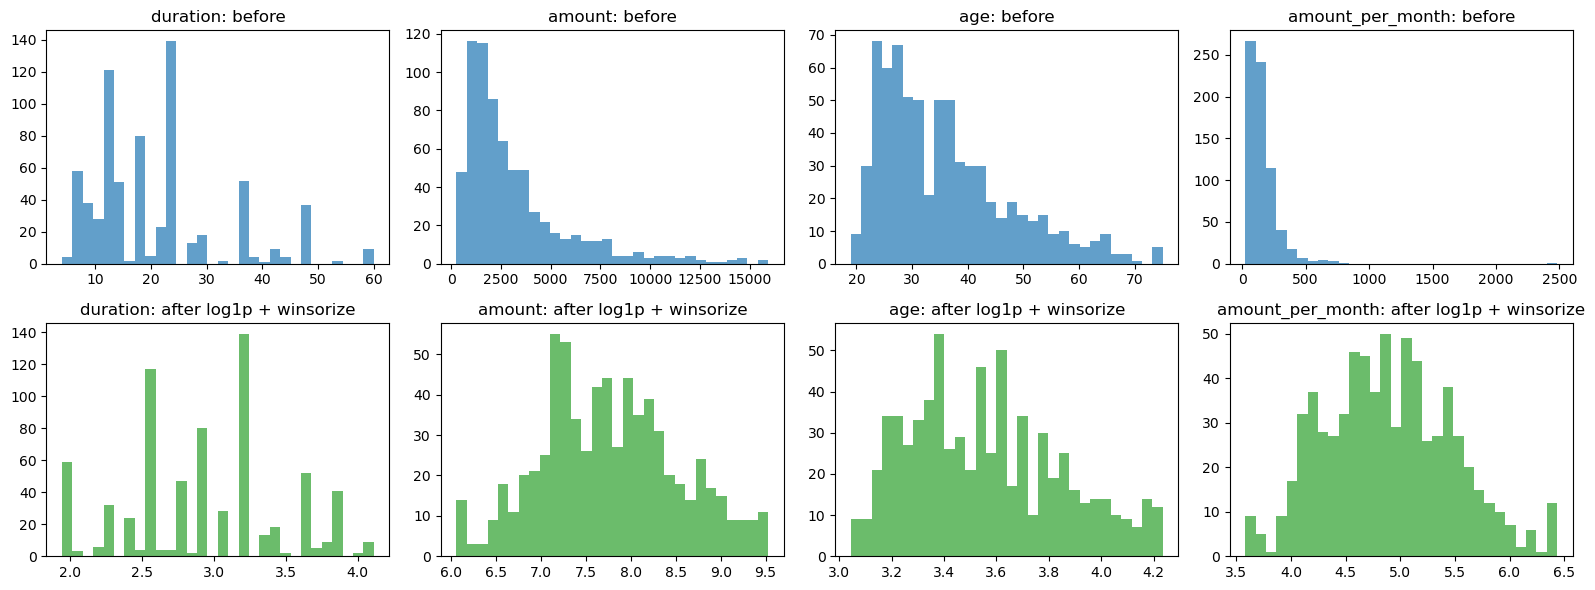

In [11]:
# The skewness outliers handling
skew_outlier_steps=[
    ('log', FunctionTransformer(np.log1p, feature_names_out='one-to-one')),
    ('winsorize', Winsorizer(lower=0.01, upper=0.99))
]

check = Pipeline(skew_outlier_steps).fit(X_train[continuous_features])

after_values = pd.DataFrame(check.transform(X_train[continuous_features]),
                            columns=continuous_features, index=X_train.index)

after = pd.DataFrame({
    'skewness': after_values.skew().round(2),
    'iqr_outliers':[count_outliers(after_values[c]) for c in continuous_features]
})
display(after)

fig, axes = plt.subplots(2, len(continuous_features), figsize=(16, 6))
for i, column in enumerate(continuous_features):
    axes[0, i].hist(X_train[column], bins=30, color='tab:blue', alpha=0.7)
    axes[0, i].set_title(f'{column}: before')
    axes[1, i].hist(after_values[column], bins=30, color='tab:green', alpha=0.7)
    axes[1, i].set_title(f'{column}: after log1p + winsorize')
plt.tight_layout()
plt.show()

### 5. Feature Scaling
StandardScaler (mean 0, standard deviation 1, learned form the train set) is applied to the continuous columns and to the ordinal columnsm, so that distance-based and regularised models (logistic regression, KNN, SVM) are not dominated by the columns with bigger numbers. One-hot and binary columns are left as 0/1.

In [17]:
continuous_pipeline = Pipeline(skew_outlier_steps + [('scale', StandardScaler())])

preprocessor = ColumnTransformer(
    transformers=[
        ('continuous', continuous_pipeline, continuous_features),
        ('ordinal', StandardScaler(), ordinal_features),
        ('nominal', OneHotEncoder(handle_unknown='ignore', drop='if_binary', sparse_output=False), nominal_features),
        ('binary', 'passthrough', binary_flags)
    ],
    remainder='drop',
    verbose_feature_names_out=False
).set_output(transform='pandas')

X_train_t = preprocessor.fit_transform(X_train)
X_test_t = preprocessor.transform(X_test)

print('Train after transform:', X_train_t.shape)
print('Test after transform', X_test_t.shape)
display(X_train_t.head())

Train after transform: (700, 52)
Test after transform (300, 52)


,duration,amount,age,amount_per_month,employment_duration,installment_rate,present_residence,property,number_credits,job,...,other_installment_plans_2,other_installment_plans_3,housing_1,housing_2,housing_3,people_liable_2,telephone_2,foreign_worker_2,is_young,long_duration
247,0.512818,0.745157,0.089218,0.454860,-0.305943,-0.843074,0.128016,-0.345607,1.057262,0.148045,...,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0,0
667,-0.558022,-1.276914,-1.299726,-1.123672,-1.126480,0.934492,1.024127,-1.301831,1.057262,0.148045,...,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,1,0
191,1.236863,0.598834,-0.771674,-0.419815,-0.305943,-0.843074,-0.768095,0.610618,-0.696490,0.148045,...,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0,0
181,0.005974,-1.043205,-0.423012,-1.368952,-1.126480,0.934492,-1.664207,-0.345607,1.057262,0.148045,...,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0,0
368,-0.311409,-0.671142,-0.651467,-0.583705,-0.305943,-0.843074,1.024127,0.610618,-0.696490,0.148045,...,0.0,1.0,1.0,0.0,0.0,1.0,0.0,1.0,0,0


In [ ]:
# sanity check 
# verify that the data feature distributions are free from obvious errors
assert list(X_train_t.columns) == list(X_test_t.columns)
assert X_train_t.isna().sum().sum() == 0 and X_test_t.isna().sum().sum() == 0

scaled_cols = continuous_features + ordinal_features
print('Scaled columns in train (should be either 0 or 1):')
display(X_train_t[scaled_cols].agg(['mean','std']).round(2))
print('Number of one-hot columns:', X_train_t.shape[1] - len(scaled_cols) - len(binary_flags))

Scaled columns in train (should be around 0-1):


,duration,amount,age,amount_per_month,employment_duration,installment_rate,present_residence,property,number_credits,job
mean,0.0,-0.0,-0.0,0.0,0.0,0.0,-0.0,0.0,-0.0,-0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


Number of one-hot columns: 40


### 6. Handling Class Imbalance (Train Set)
The train set is 70% good and 30% bad. Smote creates new synthetic bac applicants by interpolating between neighbouring real bad applicants until both classes are the same size. This only applied to train set only, runs after encoding and scaling, and both the original and the balanced train sets are saved. 

In [ ]:
# run pip install if needed
# %pip install imbalanced-learn

Note: you may need to restart the kernel to use updated packages.


In [25]:
print('Train class counts before SMOTE:')
print(y_train.value_counts().sort_index().rename({0:'bad', 1:'good'}))

smote = SMOTE(random_state=RANDOM_STATE)
X_train_res, y_train_res = smote.fit_resample(X_train_t, y_train)

print('\nTrain class counts after SMOTE:')
print(y_train_res.value_counts().sort_index().rename({0:'bad', 1:'good'}))
print('\nTrain class counts unchanged:')
print(y_test.value_counts().sort_index().rename({0:'bad', 1:'good'}))

Train class counts before SMOTE:
credit_risk
bad     210
good    490
Name: count, dtype: int64

Train class counts after SMOTE:
credit_risk
bad     490
good    490
Name: count, dtype: int64

Train class counts unchanged:
credit_risk
bad      90
good    210
Name: count, dtype: int64


### 7. Save Transformation
files saved to Dataset/processed/

In [26]:
processed_folder = raw_folder.parent / 'processed'
processed_folder.mkdir(parents=True, exist_ok=True)

joblib.dump(preprocessor, processed_folder / 'preprocessor.joblib')

X_train_t.to_csv(processed_folder / 'X_train.csv', index=False)
y_train.to_csv(processed_folder / 'y_train.csv', index=False)
X_train_res.to_csv(processed_folder / 'X_train_resampled.csv', index=False)
y_train_res.to_csv(processed_folder / 'y_train_resampled.csv', index=False)
X_test_t.to_csv(processed_folder / 'X_test.csv', index=False)
y_test.to_csv(processed_folder / 'y_test.csv', index=False)

print('Saved to:', processed_folder.resolve())
for path in sorted(processed_folder.iterdir()):
    print(' ', path.name)

Saved to: C:\Users\asus\Documents\Binus\Binus Alsut\SEM 5\DATA MINING\Group Project\CreditRiskClassificationProject\Dataset\processed
  preprocessor.joblib
  X_test.csv
  X_train.csv
  X_train_resampled.csv
  y_test.csv
  y_train.csv
  y_train_resampled.csv


### Note: 
Later if we want to run the Data Mining (Train the models) in another ipynb file, use the code below to import the files. If not then just continue it from here

joblib file is only just when we want to use a new raw data and transform applicants who are not already in the og CSV

In [ ]:
# import pandas as pd

# processed = 'Dataset/processed/'
# X_train = pd.read_csv(processed + 'X_train_resampled.csv')
# y_train = pd.read_csv(processed + 'y_train_resampled.csv').squeeze()
# X_test  = pd.read_csv(processed + 'X_test.csv')
# y_test  = pd.read_csv(processed + 'y_test.csv').squeeze()

In [ ]:
# import joblib

# preprocessor = joblib.load('Dataset/processed/preprocessor.joblib')

# # raw_new_rows must have the same columns as X_train (including the 3 engineered ones)
# X_new_t = preprocessor.transform(raw_new_rows)   # transform only, never fit again